# Notebook 1 — Data Loading & Exploration
**Thesis:** Explainable ML Framework for Detecting & Managing Data Drift in NLP Models

**Student:** Abdul Basit Naveed | DS-035/2025

**What this notebook does:**
- Loads Amazon Electronics dataset
- Explores data statistics
- Creates sentiment labels
- Saves clean data for next notebook

## Step 1 — Import Libraries

In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import warnings
import os
warnings.filterwarnings('ignore')

# Create output folder
os.makedirs('../outputs', exist_ok=True)
os.makedirs('../models', exist_ok=True)

print('All libraries loaded ✓')

All libraries loaded ✓


## Step 2 — Load Dataset

In [2]:
# ⚠️ Change this path to your file location
FILE_PATH = r'D:\Electronics.jsonl'
MAX_RECORDS = 200000  # 200k records — enough for thesis

records = []
with open(FILE_PATH, 'r', encoding='utf-8') as f:
    for i, line in enumerate(tqdm(f, desc='Loading dataset')):
        if i >= MAX_RECORDS:
            break
        try:
            records.append(json.loads(line))
        except:
            continue

df = pd.DataFrame(records)
print(f'\nTotal records loaded: {len(df):,}')
print(f'Columns: {df.columns.tolist()}')

Loading dataset: 200000it [00:03, 53759.82it/s]



Total records loaded: 200,000
Columns: ['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']


## Step 3 — Data Exploration

In [3]:
print('=== DATASET OVERVIEW ===')
print(f'Shape: {df.shape}')
print(f'\nMissing Values:')
print(df[['rating','text','timestamp']].isnull().sum())
print(f'\nRating Distribution:')
print(df['rating'].value_counts().sort_index())

=== DATASET OVERVIEW ===
Shape: (200000, 10)

Missing Values:
rating       0
text         0
timestamp    0
dtype: int64

Rating Distribution:
rating
1.0     16734
2.0      9059
3.0     14144
4.0     29427
5.0    130636
Name: count, dtype: int64


In [7]:
# Convert timestamp to year
df['timestamp'] = pd.to_datetime(df['timestamp'], unit='ms', errors='coerce')
df['year'] = df['timestamp'].dt.year

print(f'Year Range: {df["year"].min()} to {df["year"].max()}')
print(f'\nReviews per Year:')
print(df['year'].value_counts().sort_index())

Year Range: 1999 to 2023

Reviews per Year:
year
1999        1
2000        3
2001       16
2002       32
2003       33
2004       71
2005      111
2006      178
2007      406
2008      548
2009      680
2010     1133
2011     2174
2012     3328
2013     6639
2014     9841
2015    13805
2016    15914
2017    16276
2018    18723
2019    29391
2020    27432
2021    25006
2022    23211
2023     5048
Name: count, dtype: int64


## Step 4 — Create Sentiment Labels

In [8]:
def get_sentiment(rating):
    if rating >= 4:
        return 'positive'
    elif rating == 3:
        return 'neutral'
    else:
        return 'negative'

df['rating'] = df['rating'].astype(float)
df['sentiment'] = df['rating'].apply(get_sentiment)
df['label'] = df['sentiment'].map({'negative': 0, 'neutral': 1, 'positive': 2})

# Keep only needed columns
df_clean = df[['text','rating','sentiment','label','year']].dropna()
df_clean = df_clean[df_clean['text'].str.len() > 10]  # Remove very short reviews

print('Sentiment Distribution:')
print(df_clean['sentiment'].value_counts())
print(f'\nPercentage:')
print((df_clean['sentiment'].value_counts(normalize=True)*100).round(1))
print(f'\nClean dataset size: {len(df_clean):,}')

Sentiment Distribution:
sentiment
positive    154009
negative     25493
neutral      13862
Name: count, dtype: int64

Percentage:
sentiment
positive    79.6
negative    13.2
neutral      7.2
Name: proportion, dtype: float64

Clean dataset size: 193,364


## Step 5 — Visualization Graphs

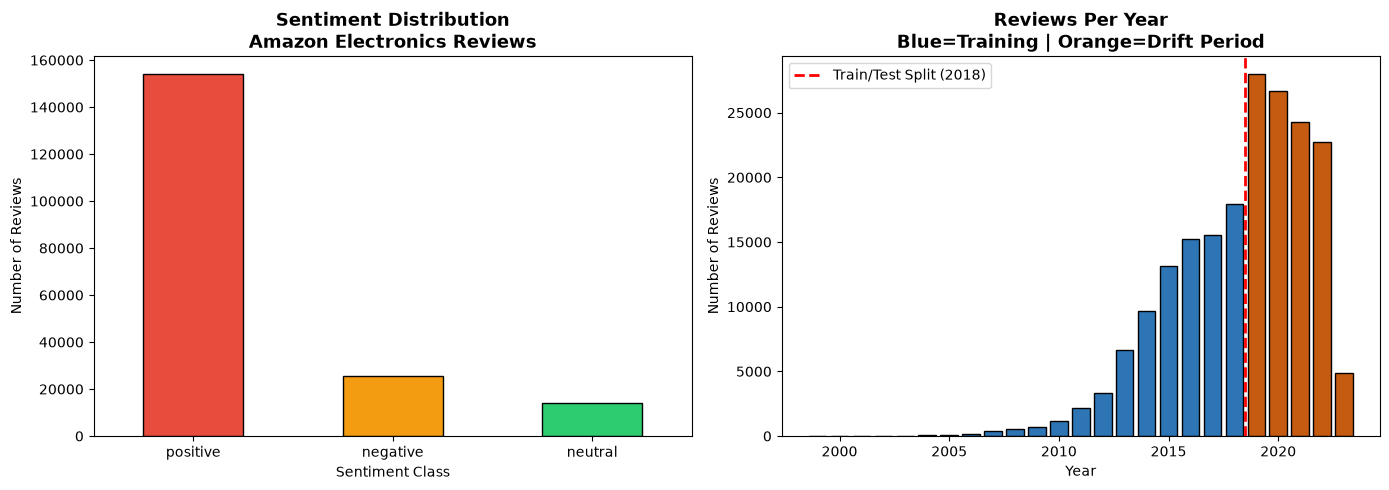

Graph saved to outputs/01_data_exploration.png ✓


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graph 1 — Sentiment Distribution
colors = ['#e74c3c', '#f39c12', '#2ecc71']
df_clean['sentiment'].value_counts().plot(
    kind='bar', ax=axes[0], color=colors, edgecolor='black'
)
axes[0].set_title('Sentiment Distribution\nAmazon Electronics Reviews', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Sentiment Class')
axes[0].set_ylabel('Number of Reviews')
axes[0].tick_params(rotation=0)

# Graph 2 — Reviews Per Year
year_counts = df_clean.groupby('year').size()
bar_colors = ['#2E75B6' if y <= 2018 else '#C55A11' for y in year_counts.index]
axes[1].bar(year_counts.index, year_counts.values, color=bar_colors, edgecolor='black')
axes[1].axvline(x=2018.5, color='red', linestyle='--', linewidth=2, label='Train/Test Split (2018)')
axes[1].set_title('Reviews Per Year\nBlue=Training | Orange=Drift Period', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Number of Reviews')
axes[1].legend()

plt.tight_layout()
plt.savefig('../outputs/01_data_exploration.png', dpi=150, bbox_inches='tight')
plt.show()
print('Graph saved to outputs/01_data_exploration.png ✓')

## Step 6 — Save Clean Data

In [12]:
df_clean.to_csv('clean_data.csv', index=False)
print(f'Clean data saved to data/clean_data.csv ✓')
print(f'Total records: {len(df_clean):,}')
print(f'Year range: {df_clean["year"].min()} — {df_clean["year"].max()}')
print('\n✅ Notebook 1 Complete! Run Notebook 2 next.')

Clean data saved to data/clean_data.csv ✓
Total records: 193,364
Year range: 1999 — 2023

✅ Notebook 1 Complete! Run Notebook 2 next.
